In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys, os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from NNMFit.utilities import ScanHandler

# import plotting utils
sys.path.append( "/data/user/tvaneede/utils" )
from FlavourScansPlotting import get_contour_points, get_contour_points_angle

# import scanning points
from flavor_fracs import *
points = pd.read_pickle('/data/user/tvaneede/GlobalFit/custom_scan_flavor/default_custom_scan_points_flavor.pickle')
flavs = flavor_frac(np.asarray(points['astro_nue_ratio']),np.asarray(points['astro_nutau_ratio']))

# import plotting flavor triangle
sys.path.append( "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks" )
from plot_utils_triangle import *


In [3]:
plotting_path = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/prompt_muon_sensitivity/sensitivity"
os.system(f"mkdir -p {plotting_path}")

0

In [5]:
dag_path       = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/dag_scans/flavor_globalfit"
hese_path      = f"{dag_path}/hese"

scan_dir_dict = {
    "benchmark" : f"{hese_path}/Poisson/hese_HESEBestfit_SPL_noinel_nosyst/",

    "reproduce" : f"{hese_path}/prompt_muons/benchmark/",
    "reproduce_paper" : f"{hese_path}/prompt_muons/benchmark_paper/",
    "conv_nothreshold" : f"{hese_path}/prompt_muons/conv_nothreshold/",
    "conv_60threshold" : f"{hese_path}/prompt_muons/conv_60threshold/",
    "conv_prompt" : f"{hese_path}/prompt_muons/conv_prompt/",
    "conv_prompt_noprior" : f"{hese_path}/prompt_muons/conv_prompt_noprior/",

}

In [6]:
# load the data
N_grid = 20
drop_unsuccessful = False
scan_dict = {}
data = {}
for name, scan_dir in scan_dir_dict.items():
    print(name)
    scan_dict[name] = ScanHandler(scan_dir,dump=False,drop_unsuccessful=drop_unsuccessful)
    data[name] = {}
    data[name]["ftau"],data[name]["fe"],data[name]["ts"],data[name]["ftau_grid"],data[name]["fe_grid"],data[name]["ts_grid"] = get_contour_points(scan_dict,name, N_grid=N_grid)


benchmark
removed stuff
reproduce
removed stuff
reproduce_paper
removed stuff
conv_nothreshold
removed stuff
conv_60threshold
removed stuff
conv_prompt
removed stuff
conv_prompt_noprior
removed stuff


/data/user/tvaneede/utils/Ternary.py:74: UserWarning: First parameter to grid() is false, but line properties are supplied. The grid will be enabled.
  ax.xaxis.grid(*args, **kwargs)
/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour_obj.collections[i].get_paths()
/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour_obj.collections[i].get_paths()
/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour_obj.collections[i].get_paths()
/data/user/tvaneede/GlobalFit/reco_processi

Area ratio (benchmark / benchmark) at 68%: 1.0000
Area ratio (reproduce / benchmark) at 68%: 0.9987
Area ratio (reproduce_paper / benchmark) at 68%: 1.0395


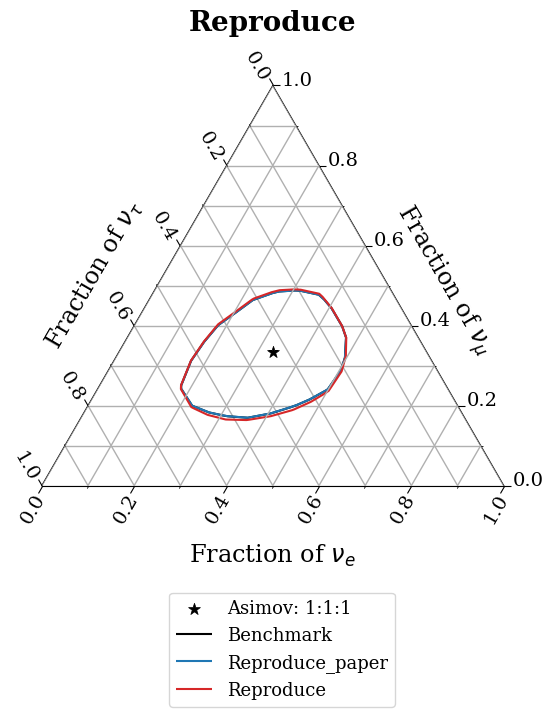

In [7]:
# compare_benchmark
names = [
"benchmark",
"reproduce",
"reproduce_paper",
]
labels = [
    "Benchmark",
    "Reproduce_paper",
    "Reproduce",
]
C = compare_contours( data = data,
                  names = names,
                  labels = labels,
                  levels = ["68%"],
                  title = "Reproduce",
                  savepath = f"{plotting_path}/reproduce_benchmark.png")

for name in names: compare_area( C, alt_key=name, base_key="benchmark", levels=["68%"] )

Area ratio (reproduce / reproduce) at 68%: 1.0000
Area ratio (reproduce_paper / reproduce) at 68%: 1.0408
Area ratio (conv_nothreshold / reproduce) at 68%: 1.1247
Area ratio (conv_60threshold / reproduce) at 68%: 1.1659
Area ratio (conv_prompt / reproduce) at 68%: 1.2826
Area ratio (conv_prompt_noprior / reproduce) at 68%: 1.3570


/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour_obj.collections[i].get_paths()
/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour_obj.collections[i].get_paths()
/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour_obj.collections[i].get_paths()
/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour

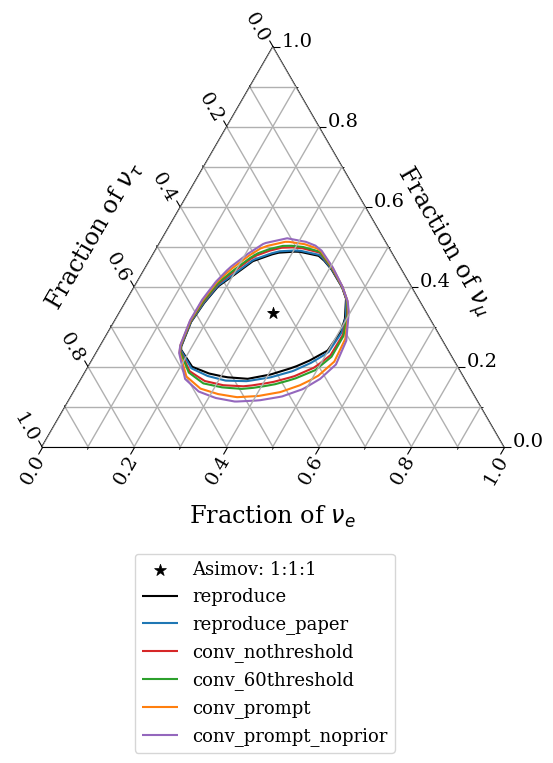

In [8]:
# compare_all
names = [
"reproduce",
"reproduce_paper",
"conv_nothreshold",
"conv_60threshold",
"conv_prompt",
"conv_prompt_noprior",
]
labels = [
    "reproduce",
    "reproduce_paper",
    "conv_nothreshold",
    "conv_60threshold",
    "conv_prompt",
    "conv_prompt_noprior",
]
C = compare_contours( data = data,
                  names = names,
                  labels = labels,
                  levels = ["68%"],
                  title = "",
                  savepath = f"{plotting_path}/compare_all.png")

for name in names: compare_area( C, alt_key=name, base_key="reproduce", levels=["68%"] )

Area ratio (reproduce / reproduce) at 68%: 1.0000
Area ratio (conv_nothreshold / reproduce) at 68%: 1.1247
Area ratio (conv_60threshold / reproduce) at 68%: 1.1659
Area ratio (conv_prompt / reproduce) at 68%: 1.2826


/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour_obj.collections[i].get_paths()
/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour_obj.collections[i].get_paths()
/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour_obj.collections[i].get_paths()
/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour

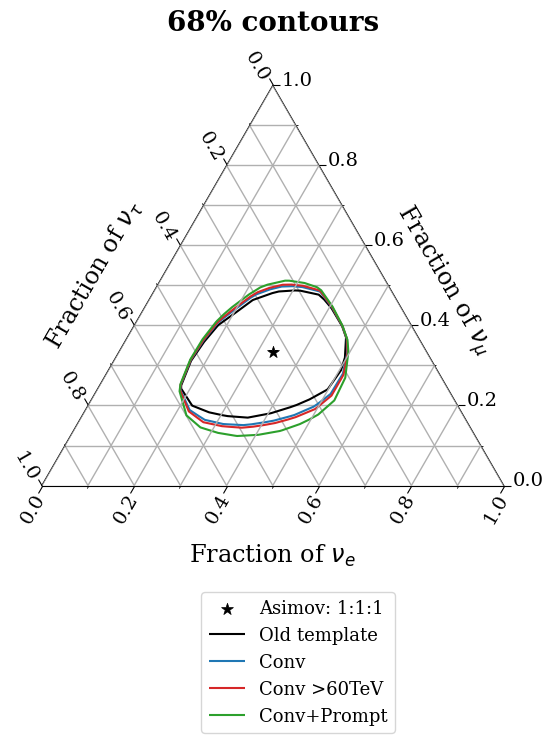

In [11]:
# compare_all
names = [
"reproduce",
"conv_nothreshold",
"conv_60threshold",
"conv_prompt",
]
labels = [
    "Old template",
    "Conv",
    "Conv >60TeV",
    "Conv+Prompt",
]
C = compare_contours( data = data,
                  names = names,
                  labels = labels,
                  levels = ["68%"],
                  title = "68% contours",
                  savepath = f"{plotting_path}/plot_presentation.png")

for name in names: compare_area( C, alt_key=name, base_key="reproduce", levels=["68%"] )

Area ratio (reproduce_paper / reproduce_paper) at 68%: 1.0000
Area ratio (conv_nothreshold / reproduce_paper) at 68%: 1.0806
Area ratio (conv_60threshold / reproduce_paper) at 68%: 1.1202
Area ratio (conv_prompt / reproduce_paper) at 68%: 1.2323


/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour_obj.collections[i].get_paths()
/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour_obj.collections[i].get_paths()
/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour_obj.collections[i].get_paths()
/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour

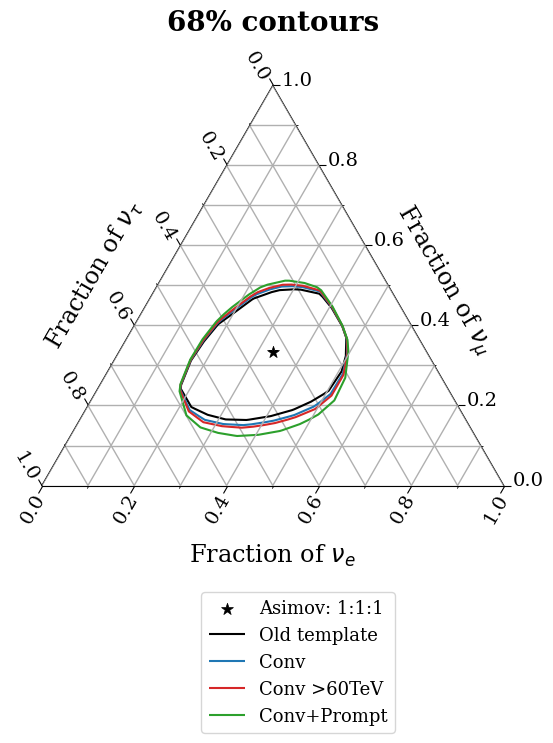

In [12]:
# compare_all_paper
names = [
"reproduce_paper",
"conv_nothreshold",
"conv_60threshold",
"conv_prompt",
]
labels = [
    "Old template",
    "Conv",
    "Conv >60TeV",
    "Conv+Prompt",
]
C = compare_contours( data = data,
                  names = names,
                  labels = labels,
                  levels = ["68%"],
                  title = "68% contours",
                  savepath = f"{plotting_path}/plot_presentation_paper.png")

for name in names: compare_area( C, alt_key=name, base_key="reproduce_paper", levels=["68%"] )

Area ratio (reproduce_paper / reproduce_paper) at 68%: 1.0000
Area ratio (conv_nothreshold / reproduce_paper) at 68%: 1.0806
Area ratio (conv_60threshold / reproduce_paper) at 68%: 1.1202
Area ratio (conv_prompt_noprior / reproduce_paper) at 68%: 1.3038


/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour_obj.collections[i].get_paths()
/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour_obj.collections[i].get_paths()
/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour_obj.collections[i].get_paths()
/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/plot_utils_triangle.py:233: MatplotlibDeprecationWarning: The collections attribute was deprecated in Matplotlib 3.8 and will be removed in 3.10.
  paths = contour

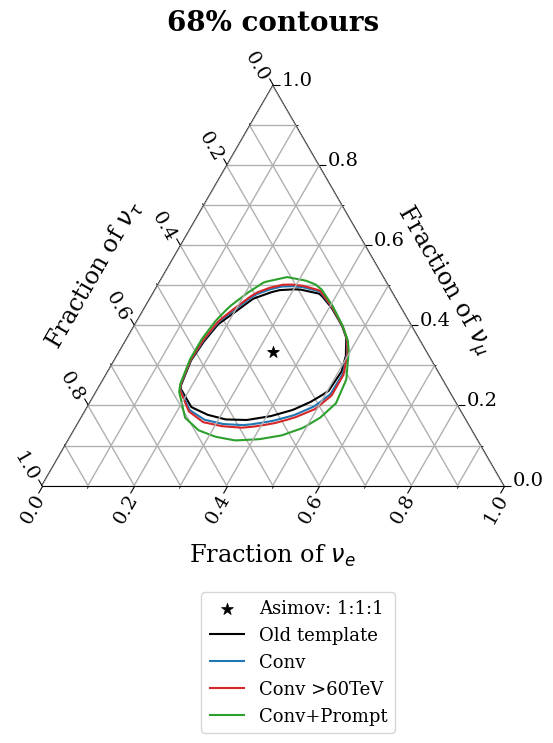

In [13]:
# compare_all_paper
names = [
"reproduce_paper",
"conv_nothreshold",
"conv_60threshold",
"conv_prompt_noprior",
]
labels = [
    "Old template",
    "Conv",
    "Conv >60TeV",
    "Conv+Prompt",
]
C = compare_contours( data = data,
                  names = names,
                  labels = labels,
                  levels = ["68%"],
                  title = "68% contours",
                  savepath = f"{plotting_path}/plot_presentation_paper_noprior.png")

for name in names: compare_area( C, alt_key=name, base_key="reproduce_paper", levels=["68%"] )